# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Marana, Kyle
- _Student No._: 2024-14996
- _Section_: THR-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure


### Problem 1
![A](fig1.png)
**Figure 1. Sine Wave**
![A](fig2.png)
**Figure 2. Gaussian**
![A](fig3.png)
**Figure 3. Dirac-delta**

### Problem 2
![A](fig4.png)
**Figure 4. Comparing Noisy Signal vs Recovered Denoised Signal**

### Problem 3
![A](fig5.png)
**Figure 5. fs = 100Hz - Above Nyquist Frequency (No Aliasing)**
![A](fig6.png)
**Figure 6. fs = 12Hz - Below Nyquist Frequency (Aliased)**

### Report discussion
### Problem 1
The shape of the input signal determines the shape of its transform. A sine wave, which repeats at one frequency, gives a single sharp peak at that frequency. The Gaussian, which is smooth and spread out in time, gives a smooth spectrum that is concentrated near zero frequency and dies out quickly. For the Gaussian, a larger sigma makes the pulse wider in time and its spectrum narrower, while a smaller sigma does the opposite. The Dirac delta, which is a single spike in time, gives a flat spectrum, so it contains all frequencies. A signal that is narrow in time is therefore wide in frequency.

### Problem 2
Lowering N shortens the recording. The shape of the signal stays the same, but fewer cycles are captured, so the peaks in its transform become wider and less sharp. In Fig. 4, the dashed recovered signal follows the timing and shape of the original even though the noise was strong, so the signal can still be recovered when N is lowered. This works because the three frequencies stand out as peaks above the noise. There is a limit, though. If N is too small, the peaks blur into each other and sink into the noise, so the filter can no longer separate signal from noise. The recovered signal in Fig. 4 is also smaller than the original because the Hann window shrinks it.

### Problem 3
The signal being sampled is a 9 Hz sine, so the Nyquist rate is 18 Hz. In Fig. 5, fs = 100 Hz is above this, so the samples follow the real wave closely and the transform shows one peak at 9 Hz, the true frequency. In Fig. 6, fs = 12 Hz is below it, so the samples are too sparse and, when connected, form a slow zigzag that looks nothing like the real fast wave in gray. Its transform shows a peak at 3 Hz instead of 9 Hz, which is a false frequency. The two transforms are not the same.


### Other comments
- I've got real big expectations - Olivia Rodrigo, 2026


---
## Section 2: Code

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

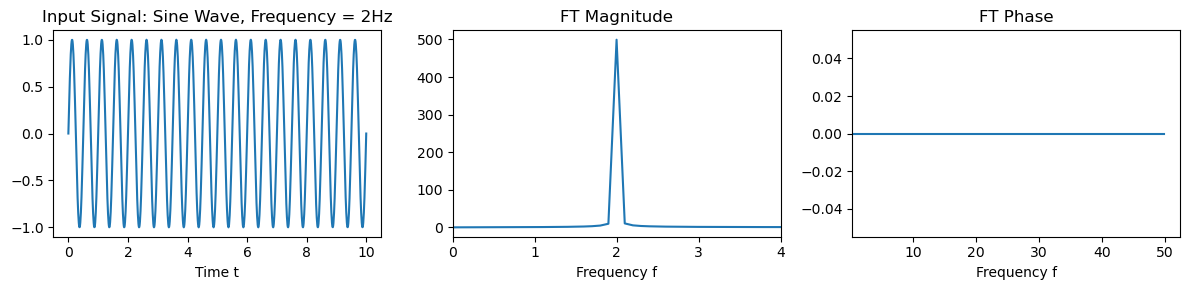

In [39]:
N = 1000
t = np.linspace(0, 10, N)
deltaT = t[1] - t[0]

f = 2
x = np.sin(2*np.pi*f*t)

freqs = np.fft.fftfreq(N, deltaT)
x_ft = np.fft.fft(x)

freqs = np.fft.fftshift(freqs)
x_ft = np.fft.fftshift(x_ft)

x_mag = np.abs(x_ft)
x_phase = np.angle(x_mag)

x_phase = np.unwrap(x_phase)
pos = freqs>=0

fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Input Signal: Sine Wave, Frequency = 2Hz")
ax[0].set_xlabel("Time t")
ax[0].plot(t, x)

ax[1].set_title("FT Magnitude")
ax[1].set_xlabel("Frequency f")
ax[1].plot(freqs[pos], x_mag[pos])
ax[1].set_xlim(0, 4)

ax[2].set_title("FT Phase")
ax[2].set_xlabel("Frequency f")
ax[2].plot(freqs[pos], x_phase[pos])
ax[2].set_xlim(0.4)

fig.tight_layout()
plt.savefig('fig1.png')
plt.show()

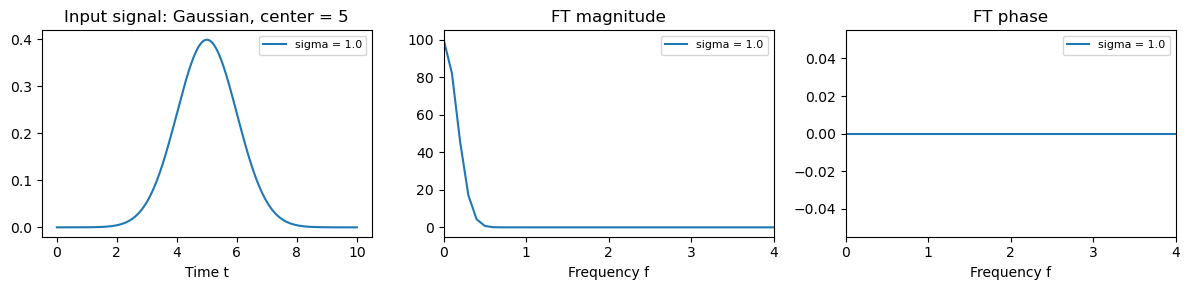

In [40]:
N = 1000
t = np.linspace(0, 10, N)
deltaT = t[1] - t[0]

t0 = 5
sigma = 1.0

freqs = np.fft.fftfreq(N, deltaT)
freqs = np.fft.fftshift(freqs)

pos = freqs >= 0

fig, ax = plt.subplots(1, 3, figsize=(12, 3))

x = 1 / (sigma * np.sqrt(2*np.pi)) * np.exp(-(t - t0)**2 / (2 * sigma**2))

x_ft = np.fft.fft(x)
x_ft = np.fft.fftshift(x_ft)
x_mag = np.abs(x_ft)
x_phase = np.angle(x_mag)
x_phase = np.unwrap(x_phase)

ax[0].plot(t, x, label=f"sigma = {sigma}")
ax[1].plot(freqs[pos], x_mag[pos], label=f"sigma = {sigma}")
ax[2].plot(freqs[pos], x_phase[pos], label=f"sigma = {sigma}")

ax[0].set_title("Input signal: Gaussian, center = 5")
ax[0].set_xlabel("Time t")

ax[1].set_title("FT magnitude")
ax[1].set_xlabel("Frequency f")
ax[1].set_xlim(0, 4)

ax[2].set_title("FT phase")
ax[2].set_xlabel("Frequency f")
ax[2].set_xlim(0, 4)

for a in ax:
    a.legend(fontsize=8)

fig.tight_layout()
plt.savefig('fig2.png')
plt.show()

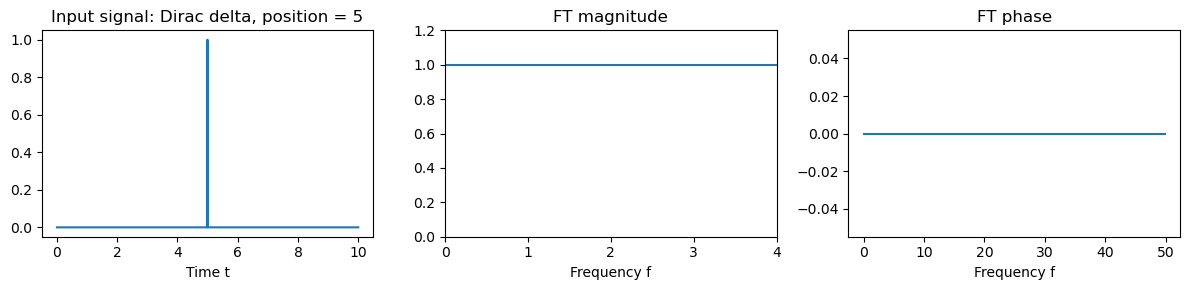

In [41]:
N = 1000
t = np.linspace(0, 10, N)
deltaT = t[1] - t[0]

t0 = 5
x = np.zeros(N)
x[np.argmin(np.abs(t - t0))] = 1

freqs = np.fft.fftfreq(N, deltaT)
x_ft = np.fft.fft(x)

freqs = np.fft.fftshift(freqs)
x_ft = np.fft.fftshift(x_ft)

x_mag = np.abs(x_ft)
x_phase = np.angle(x_mag)

x_phase = np.unwrap(x_phase)

pos = freqs >= 0

fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].plot(t, x)
ax[1].plot(freqs[pos], x_mag[pos])
ax[2].plot(freqs[pos], x_phase[pos])

ax[0].set_title("Input signal: Dirac delta, position = 5")
ax[0].set_xlabel("Time t")

ax[1].set_title("FT magnitude")
ax[1].set_xlabel("Frequency f")
ax[1].set_xlim(0, 4)
ax[1].set_ylim(0, 1.2)

ax[2].set_title("FT phase")
ax[2].set_xlabel("Frequency f")

fig.tight_layout()
plt.savefig('fig3.png')
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [6]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]



signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

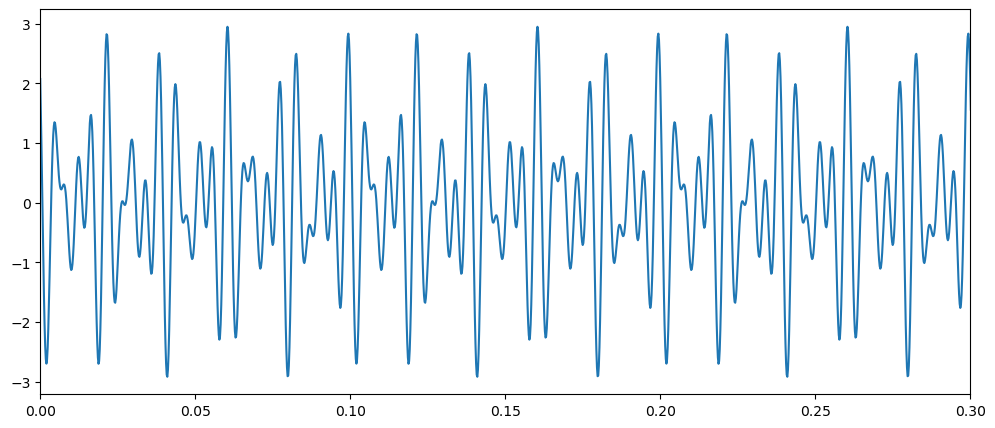

In [7]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)

In [8]:
#FILL: Plot the fourier transform of the clean, original signal

Text(0, 0.5, '|FT|')

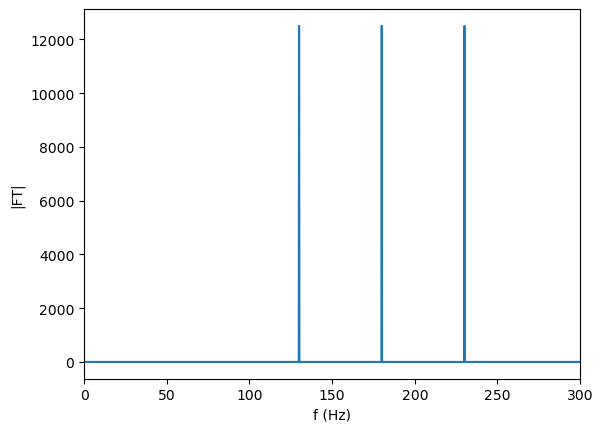

In [9]:
cleanFourier = np.fft.fftshift(np.fft.fft(signal_original))
cleanFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))
plt.plot(cleanFreqs, np.abs(cleanFourier))
plt.xlim(0, 300)
plt.xlabel("f (Hz)"); plt.ylabel("|FT|")

In [10]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

(0.0, 0.3)

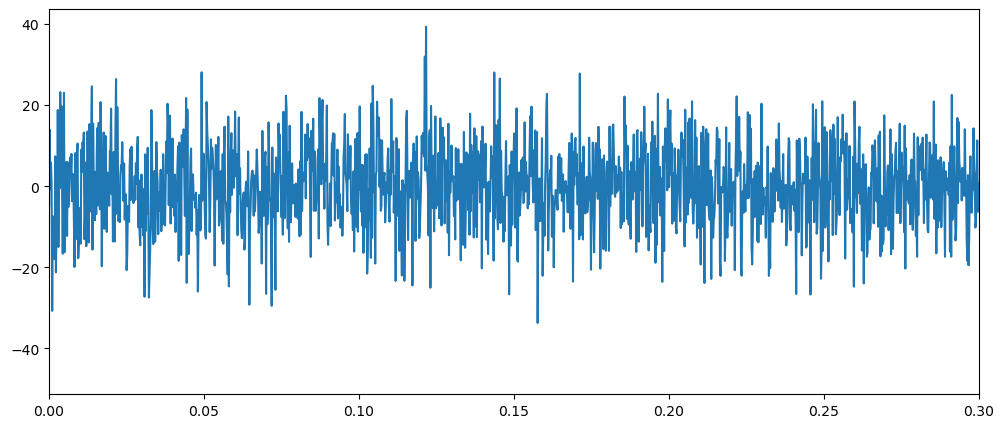

In [11]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)

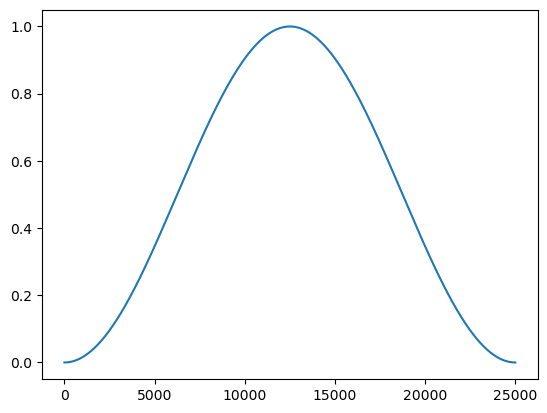

In [12]:
window = np.hanning(len(noisy_data))

#Create a window the size of the data length
plt.plot(window)

In [13]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

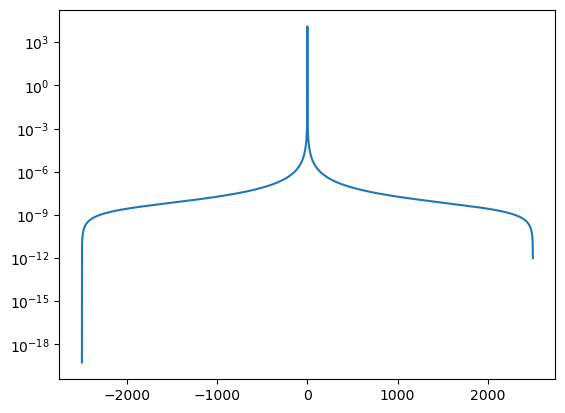

In [14]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [15]:
noisyFourier = np.fft.fft(noisy_data*window)

# noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))


Text(0, 0.5, '|FT|')

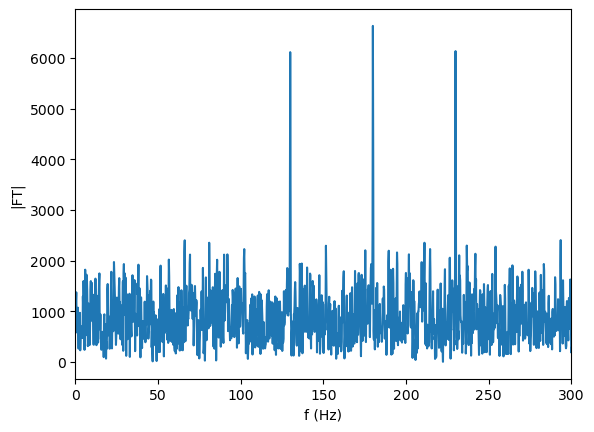

In [16]:
# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window
noisyMag = np.abs(np.fft.fftshift(noisyFourier))
plt.plot(windowSigFreqs, noisyMag)
plt.xlim(0, 300)
plt.xlabel("f (Hz)"); plt.ylabel("|FT|")

(0.0, 300.0)

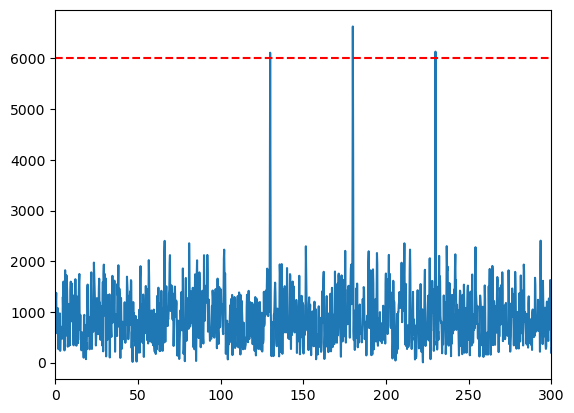

In [31]:
# Fill: Find a suitable threshold value to filter the noise in fourier space

threshold =6000
plt.plot(windowSigFreqs, noisyMag)
plt.axhline(threshold, color="r", ls="--")
plt.xlim(0, 300)

In [32]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain

cleanedFourier = np.where(np.abs(noisyFourier) > threshold, noisyFourier, 0)
recoveredSignal = np.fft.ifft(cleanedFourier).real

/tmp/ipykernel_201/671899362.py:6: RuntimeWarning: divide by zero encountered in divide
  recovered = np.where(window > 0.5, recoveredSignal / window, np.nan)


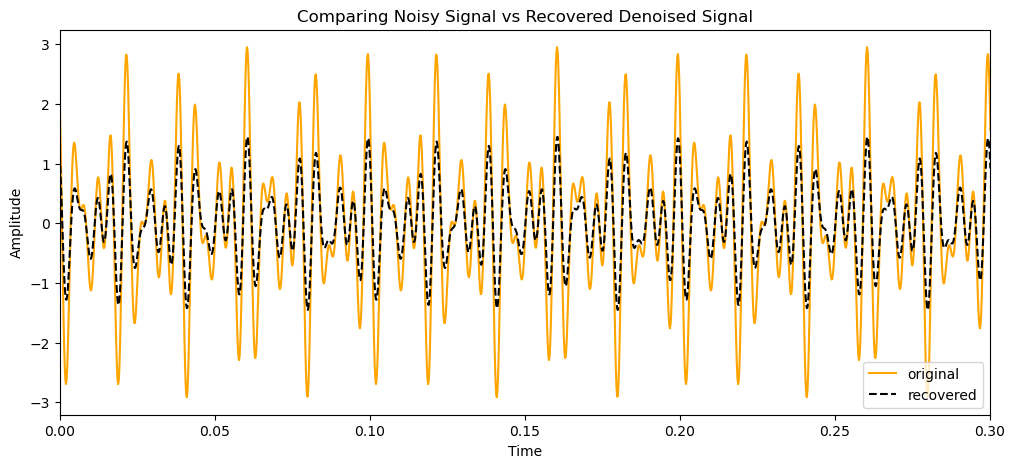

In [42]:
# Plot the recovered signal
# fig, ax = plt.subplots(figsize= (12,5))
# ax.plot(t_, recoveredSignal)
# ax.set_xlim(0,0.3)# the Hann window scaled the signal, so divide it out where the window isn't near 0

recovered = np.where(window > 0.5, recoveredSignal / window, np.nan)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t_, signal_original, color='orange', label="original")
ax.plot(t_, recoveredSignal, "--", color='k',label="recovered")
#ax.plot(t_, signal_original, label='original')
ax.set_xlim(0, 0.3)
plt.title("Comparing Noisy Signal vs Recovered Denoised Signal")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.savefig('fig4.png')
ax.legend()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

fs = 100 Hz (Above Nyquist frequency (No Aliasing)): peak at 9.00 Hz


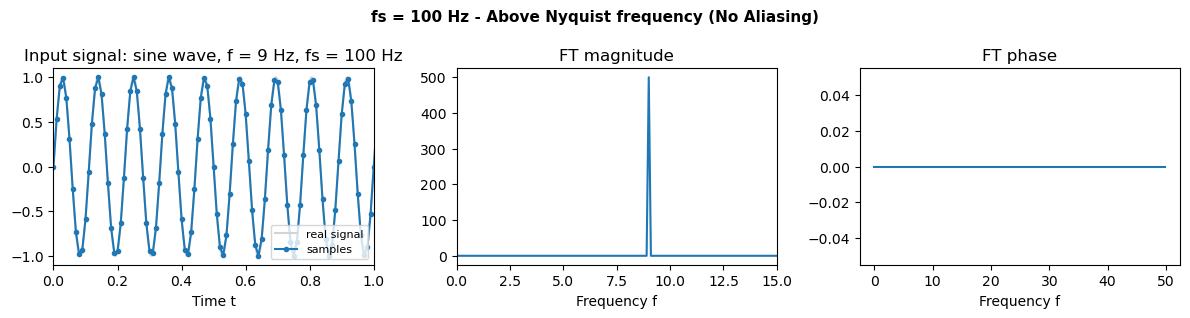

fs = 12 Hz (Below Nyquist frequency (Aliased)): peak at 3.00 Hz


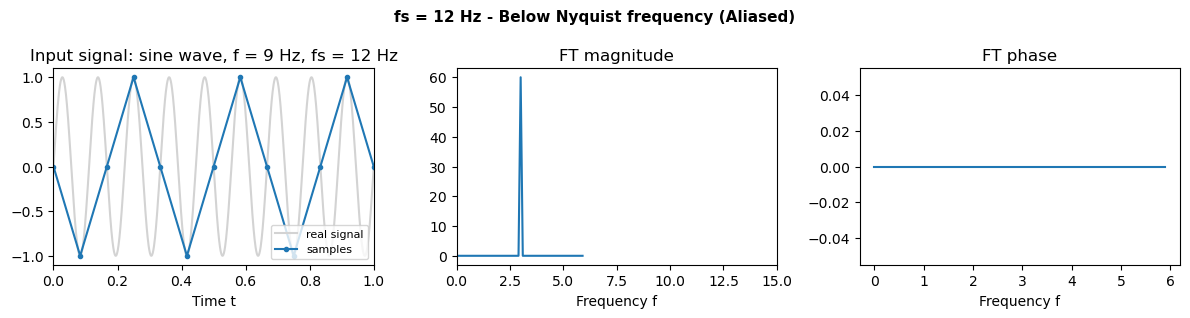

In [46]:
f = 9
T = 10
fs_list = [100, 12]

t_fine = np.linspace(0, T, 10000)
x_real = np.sin(2*np.pi*f*t_fine)

for fs in fs_list:
    f_nyquist = 2 * f
    if fs > f_nyquist:
        nyq_label = "Above Nyquist frequency (No Aliasing)"
    else:
        nyq_label = "Below Nyquist frequency (Aliased)"

    N = int(T * fs)
    t = np.linspace(0, T, N, endpoint=False)
    deltaT = t[1] - t[0]

    x = np.sin(2 * np.pi * f * t)

    freqs = np.fft.fftfreq(N, deltaT)
    x_ft = np.fft.fft(x)

    freqs = np.fft.fftshift(freqs)
    x_ft = np.fft.fftshift(x_ft)

    x_mag = np.abs(x_ft)
    x_phase = np.angle(x_mag)
    x_phase = np.unwrap(x_phase)

    pos = freqs >= 0

    print(f"fs = {fs} Hz ({nyq_label}): peak at {freqs[pos][np.argmax(x_mag[pos])]:.2f} Hz")

    fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
    fig.suptitle(f"fs = {fs} Hz - {nyq_label}", fontsize=11, fontweight="bold")

    ax[0].set_title(f"Input signal: sine wave, f = {f} Hz, fs = {fs} Hz")
    ax[0].set_xlabel("Time t")
    ax[0].plot(t_fine, x_real, color="lightgray", label="real signal")
    ax[0].plot(t, x, ".-", label="samples")
    ax[0].set_xlim(0, 1)
    ax[0].legend(fontsize=8, loc='lower right')

    ax[1].set_title("FT magnitude")
    ax[1].set_xlabel("Frequency f")
    ax[1].plot(freqs[pos], x_mag[pos])
    ax[1].set_xlim(0, 15)

    ax[2].set_title("FT phase")
    ax[2].set_xlabel("Frequency f")
    ax[2].plot(freqs[pos], x_phase[pos])

    fig.tight_layout()
    plt.savefig('fig6.png')
    plt.show()

#### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

This exercise uses NumPy’s FFT to study how signals look in frequency space. Each problem builds a signal, takes `np.fft.fft`, and applies fftshift so frequencies run from negative to positive, then plots only f ≥ 0 since real signals have a symmetric spectrum. For denoising, a Hann window reduces spectral leakage and a threshold zeroes weak coefficients before ifft, and for aliasing, the sampling frequency is looped so the Nyquist condition can be compared directly.

---
## Section 3: Notes

In [15]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

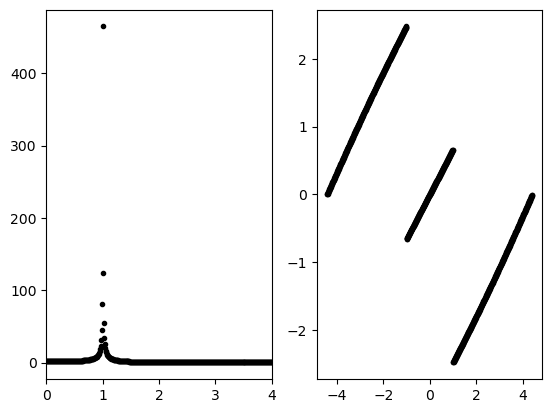

In [16]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [17]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

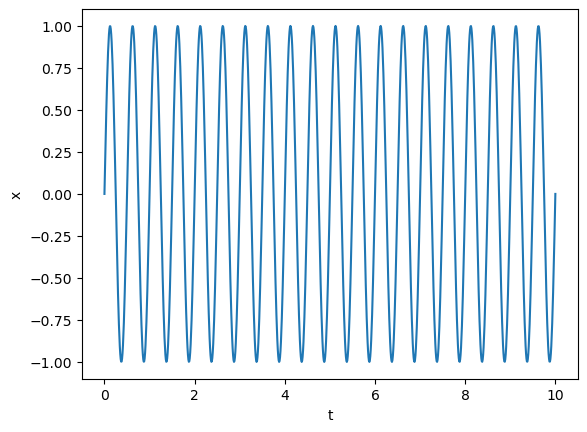

In [18]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [19]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

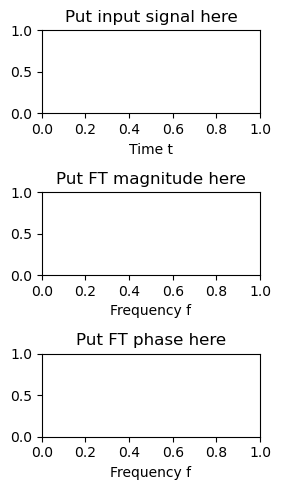

In [20]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

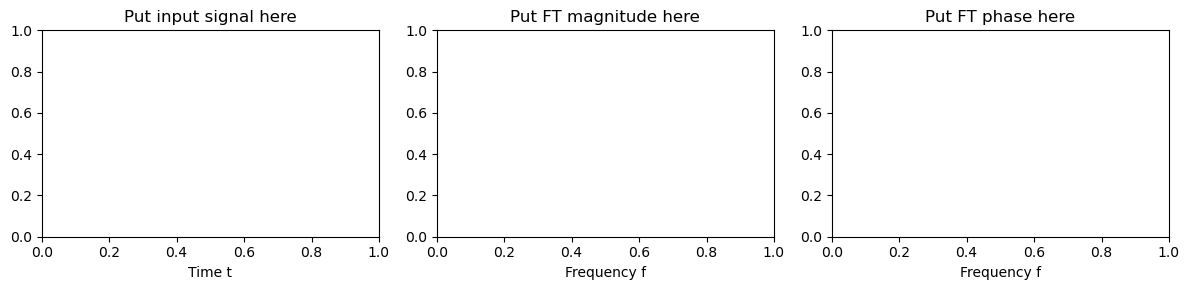

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

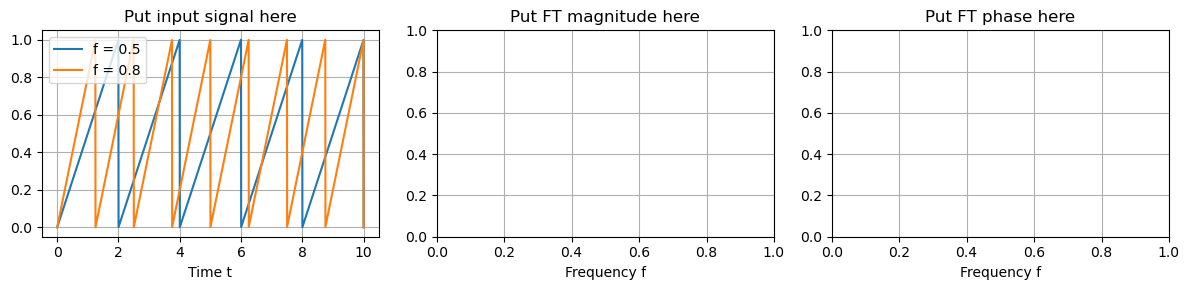

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [23]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



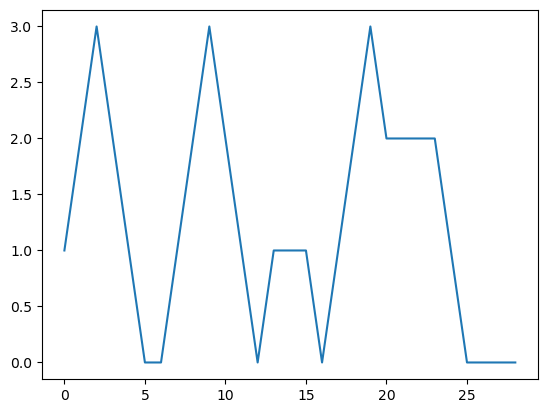

In [24]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [18]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [19]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

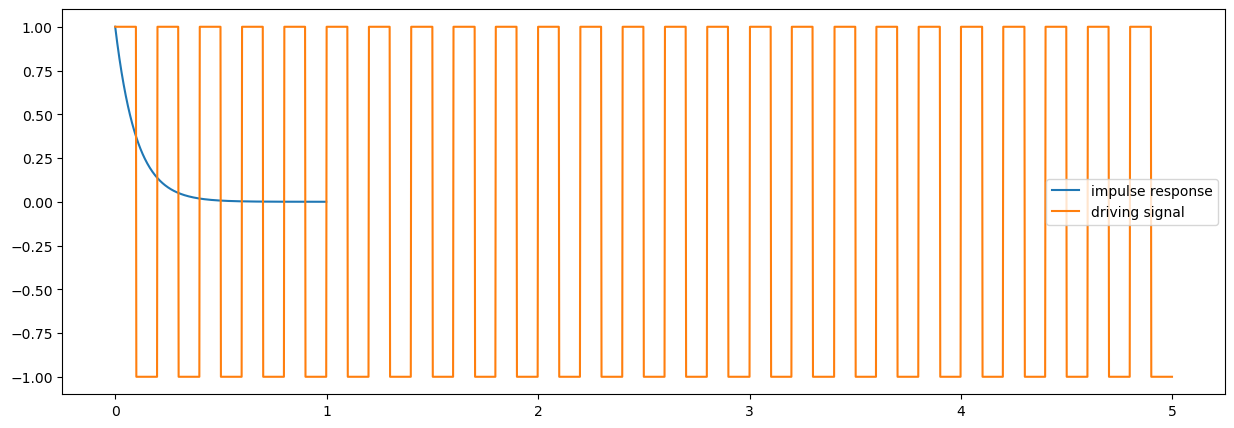

In [20]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [21]:
response = np.convolve(input_signal, h_t, mode = "same")

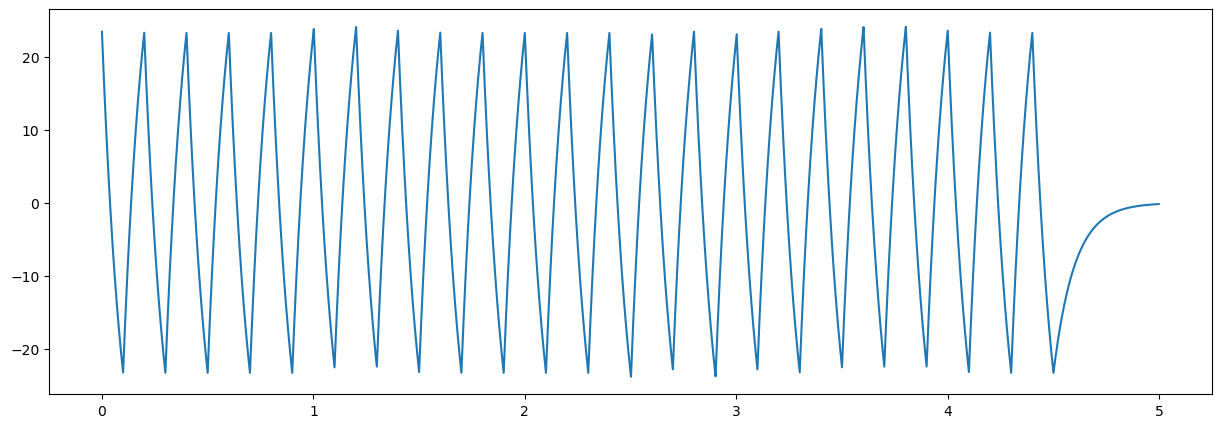

In [22]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [23]:
fourier_length = len(h_t) + len(input_signal) - 1

In [24]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [25]:
fourier_response = fourier_h*fourier_input 

In [26]:
response = np.real(np.fft.ifft(fourier_response))

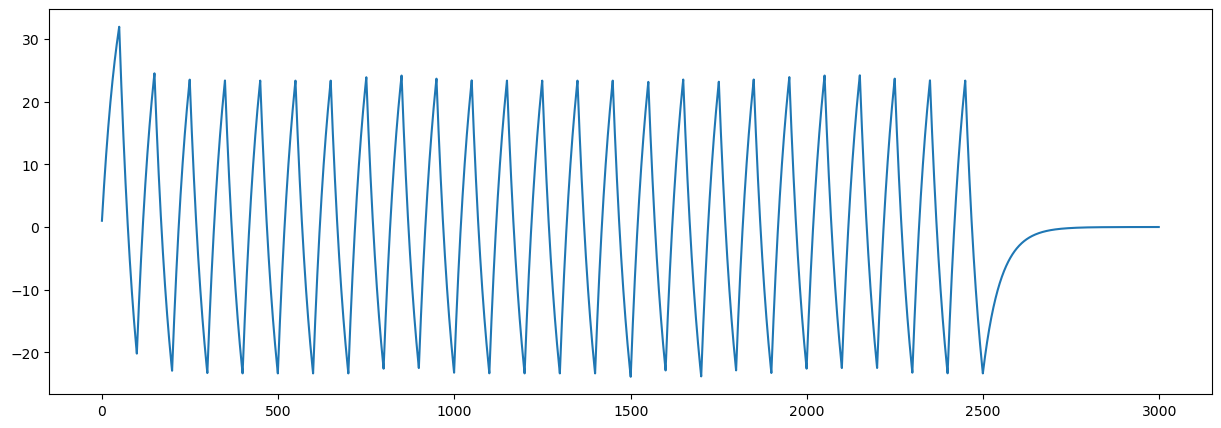

In [27]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)